# Final Evaluation

In [1]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, average_precision_score, confusion_matrix, ConfusionMatrixDisplay

In [2]:
df = pd.read_excel("../data/default of credit card clients.xls", header=1)
df.shape

(30000, 25)

In [3]:
df = df.drop(columns="ID")
df = df.drop_duplicates()
df.shape

(29965, 24)

In [4]:
df["EDUCATION"] = df["EDUCATION"].replace({0 :4, 5 :4, 6 :4})
print(df["EDUCATION"].value_counts().sort_index())

df["MARRIAGE"] = df["MARRIAGE"].replace({0 :3})
print(df["MARRIAGE"].value_counts().sort_index())

EDUCATION
1    10563
2    14019
3     4915
4      468
Name: count, dtype: int64
MARRIAGE
1    13643
2    15945
3      377
Name: count, dtype: int64


In [5]:
df = df.rename(columns={"default payment next month": "default"})

In [6]:
X = df.drop(columns="default")
y = df["default"]
print(X.shape, y.shape)

(29965, 23) (29965,)


In [7]:
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=42
)

In [8]:
print(X_train.shape, X_val.shape, X_test.shape)
print(y_train.value_counts(normalize=True))
print(y_val.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

(17979, 23) (5993, 23) (5993, 23)
default
0    0.778742
1    0.221258
Name: proportion, dtype: float64
default
0    0.778742
1    0.221258
Name: proportion, dtype: float64
default
0    0.778742
1    0.221258
Name: proportion, dtype: float64


In [9]:
cat_cols = ["SEX", "EDUCATION", "MARRIAGE"]
num_cols = [col for col in X.columns if col not in cat_cols]
print(len(cat_cols), len(num_cols))

3 20


In [10]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

## The Final model

In [11]:
forest = Pipeline([
    ("prep", preprocessor),
    ("model", RandomForestClassifier(n_estimators = 200, max_depth = 10, class_weight = "balanced", random_state = 42, n_jobs = -1))
])

forest.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['LIMIT_BAL','SEX','EDUCATION',...,'PAY_AMT4','PAY_AMT5','PAY_AMT6']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining c

## Test results

In [12]:
test_proba = forest.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= 0.35).astype(int)

print(test_pred.sum())

3077


In [13]:
print("Accuracy :", accuracy_score(y_test, test_pred))
print("Precision:", precision_score(y_test, test_pred))
print("Recall   :", recall_score(y_test, test_pred))
print("F1       :", f1_score(y_test, test_pred))
print("PR-AUC   :", average_precision_score(y_test, test_proba))

tn, fp, fn, tp = confusion_matrix(y_test, test_pred).ravel()
print("TN", tn, "FP", fp, "FN", fn, "TP", tp)

cost = 5 * fn + 1 * fp
print("Cost:", cost)

Accuracy : 0.6130485566494244
Precision: 0.338641533961651
Recall   : 0.7858220211161387
F1       : 0.473313649784238
PR-AUC   : 0.5454939781145691
TN 2632 FP 2035 FN 284 TP 1042
Cost: 3455


Here is the final result from the forest at 0.35 in the test data. On the test data, the recall is slightly lower, from 0.8 to 0.79. This is probably due to the threshold of 0.35 picked being more suited to the validation set rather than the unseen test data, so it's to be expected, and it's not a large drop off. The cost is also higher, going from 3318 to 3455, but still far lower than the baseline's 6630. I picked the 0.35 threshold based on the validation rather than picking it on the test set to keep it as an honest estimate of how the model performs on new data, as the test must be free from data leakage. If we look at FP, it is 2035, which is the cost of catching 79% of defaulters, meaning 2035 good customers who wouldn't default got flagged. However, this is acceptable because the cost of flagging a good customer is lower than missing a defaulter in this study.

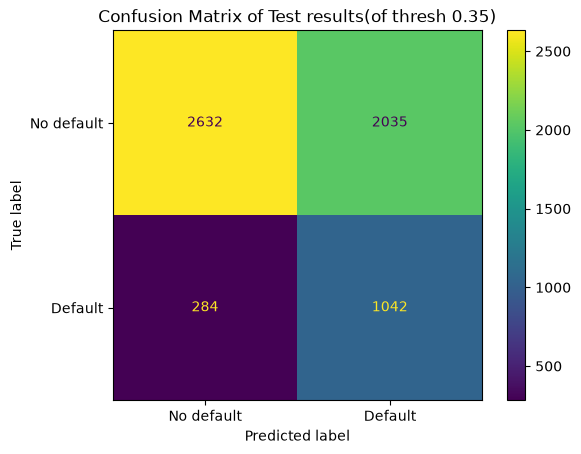

In [14]:
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels = ["No default", "Default"])
plt.title("Confusion Matrix of Test results(of thresh 0.35)")
plt.show()

## Feature Importance

In [15]:
feature_names = forest.named_steps["prep"].get_feature_names_out()
importances = forest.named_steps["model"].feature_importances_

fi = pd.Series(importances, index = feature_names).sort_values(ascending = False)
print(fi.head(10))

num__PAY_0        0.216164
num__PAY_2        0.105930
num__PAY_3        0.060711
num__PAY_4        0.053056
num__PAY_AMT1     0.048300
num__LIMIT_BAL    0.045592
num__PAY_AMT2     0.041827
num__BILL_AMT1    0.041479
num__PAY_5        0.040586
num__PAY_AMT3     0.037705
dtype: float64


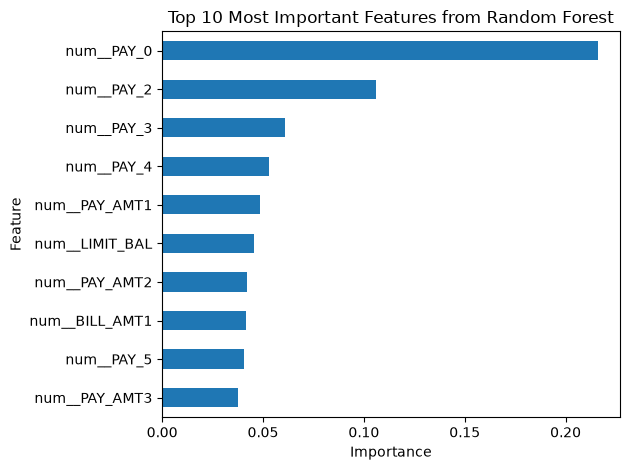

In [16]:
fi.head(10).sort_values().plot(kind = "barh")
plt.title("Top 10 Most Important Features from Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

From the bar chart above it's clear that the most important feature by far is PAY_0, as well as all other PAY features bar PAY_6 being in the top 10. This shows the model mainly looks at whether a customer paid late recently. Looking back, the defaulters that had been missed by my model were ones that had been paying on time, up until they defaulted, so the model doesn't flag them. I also noticed there are no features like SEX, AGE, EDUCATION, MARRIAGE in the top 10, so the model doesn't directly judge a defaulter based on a customer's age, gender, marriage status or education level. I will however do a further fairness check on this.

## Fairness check

### By SEX

In [17]:
fair = X_test[["SEX"]].copy()
fair["actual"] = y_test
fair["pred"] = test_pred

defaulters = fair[fair["actual"] == True]
print(defaulters.groupby("SEX")["pred"].mean())

SEX
1    0.783831
2    0.787318
Name: pred, dtype: float64


In [18]:
non_defaulters = fair[fair["actual"] == False]
print(non_defaulters.groupby("SEX")["pred"].mean())

SEX
1    0.469654
2    0.415634
Name: pred, dtype: float64


From above, it shows the model catches 78.4% of male defaulters and 78.7% of female defaulters, which is very close. However, the amount of good customers wrongly flagged are 47% of men and 41.6% of women, about a 5% difference wrongly flagged. A good customer that gets wrongly flagged is bad as they might be charged more or refused credit. The model doesn't rely heavily on SEX, so the gap might be coming from other feature patterns amongst men and women in this dataset. 

### By AGE

In [19]:
fair["age_group"] = pd.cut(X_test["AGE"], bins = [20, 30, 40, 50, 80], labels = ["21-30", "31-40", "41-50", "51 and over"])

print(fair[fair["actual"] == 1].groupby("age_group")["pred"].mean())
print(fair[fair["actual"] == 0].groupby("age_group")["pred"].mean())
print(fair["age_group"].value_counts())

age_group
21-30          0.807531
31-40          0.762014
41-50          0.775439
51 and over    0.809524
Name: pred, dtype: float64
age_group
21-30          0.475638
31-40          0.388657
41-50          0.429654
51 and over    0.485465
Name: pred, dtype: float64
age_group
21-30          2202
31-40          2112
41-50          1209
51 and over     470
Name: count, dtype: int64


Like SEX, AGE has a fairly equal recall across groups, but not so equal false alarms. The range of false alarms goes from 38.9% to 48.5%, with the 21-30 and 51 and over groups being hit the hardest. This appears to be U shaped. Age matters more than Sex, even though AGE wasn't in the top 10 features. This might be because there are other features linked to the age groups, like younger people having lower LIMIT_BAL for example. Also the 51 and over group is small at 470 so the numbers are less reliable for them.